In [27]:
from langgraph.graph import StateGraph,MessagesState,START,END
from typing import TypedDict

In [28]:
class BMIState(TypedDict):
    weight_kg:float
    height_m:float
    bmi:float   
    fitness:str 

In [29]:
def hello_world_node(state: BMIState)->BMIState:
    weight=state['weight_kg']
    height=state['height_m']

    bmi=weight/(height**2)
    print("bmi of person is ",bmi)
    state['bmi']=round(bmi,2)
    return state

In [30]:
def fitnessLevel(state:BMIState)->BMIState:
    bmi=state['bmi']

    if(bmi>6):
        state['fitness']='Your Fitness is Govinda Level'
    elif(bmi<5):
        state['fitness']='Fitnees level is Vinay'
    else:
        state['fitness']='Fitnees level is Ritik'

    return state

In [31]:
graph=StateGraph(BMIState)
graph.add_node('bmi calculator',hello_world_node)
graph.add_node('fitness level check',fitnessLevel)

graph.add_edge(START,'bmi calculator')
graph.add_edge('bmi calculator','fitness level check')
graph.add_edge('fitness level check',END)

workflow=graph.compile()

initiaState={'weight_kg':240.3,'height_m':5.10}

final_state=workflow.invoke(initiaState)

print(final_state)


bmi of person is  9.238754325259517
{'weight_kg': 240.3, 'height_m': 5.1, 'bmi': 9.24, 'fitness': 'Your Fitness is Govinda Level'}


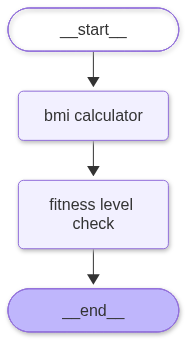

In [32]:
from IPython.display import Image, display
  # Display it inline inside the Jupyter notebook
Image(workflow.get_graph().draw_mermaid_png())